# Ketika Urutan Baris Lebih Informatif daripada Fitur: Prior Posisi dan Residual Learning

| | |
| --- | --- |
| **Kompetisi** | [Data Science Competition FIK FAIR 2026](https://www.kaggle.com/competitions/data-science-competition-fikfair2026) (UPN "Veteran" Jakarta, Kaggle, Oktober 2026) |
| **Tujuan** | Memprediksi `target` (*Anonymous Competition Score*) dari 24 fitur lingkungan/iklim yang dianonimkan (metrik RMSE) |
| **Data** | 382 baris latih, 96 baris uji (29 public, 67 private) |
| **Tim** | **Lomba Terakhir Bersama Abil**: Muhammad Abil Hasan, Naufal Arkan Wahib, Fauzan Ahsanudin Alfikri, Salsabila Rizqiyah Anwar |
| **Versi ini** | Disusun ulang oleh Fauzan Ahsanudin Alfikri · [Kaggle: fauzan2](https://www.kaggle.com/fauzan2), November 2026 |
| **Lingkungan** | Dijalankan penuh di Kaggle (CPU) |

Metode dan konfigurasi model berasal dari notebook final tim selama kompetisi. Versi ini mempertahankan metode itu
apa adanya, lalu menambahkan EDA, bukti visual, dan pembahasan hasil leaderboard.

**Pertanyaan penelitian.** Fitur yang dianonimkan hampir tidak berkorelasi dengan target, tetapi target tersusun hampir
monoton terhadap urutan baris file. Apakah urutan itu bisa dipakai dengan aman, dan seberapa banyak yang masih bisa
ditambahkan oleh 24 fitur?

**Ringkasan temuan.**
- Target tersusun hampir monoton menurun terhadap urutan baris di `train.csv` (Spearman −0,981), sedangkan fitur terkuat hanya berkorelasi 0,42 dengan target. `record_id` acak, jadi informasinya ada di urutan file.
- Korelasi setiap fitur dengan target hampir persis cermin korelasinya dengan posisi baris (korelasi antar keduanya −0,999): fitur "tahu" target hanya sejauh fitur itu ikut tersusun menurut urutan.
- Test tampaknya disusun dengan urutan yang sama: model yang hanya memakai fitur menghasilkan prediksi test yang menurun terhadap urutan baris test (Spearman −0,75, train −0,80), dan adversarial AUC train vs test hanya 0,547.
- Metode tim, **prior posisi isotonik + koreksi residual dari 24 fitur** (blend GP-ARD dan SVR, diredam 0,7×), mencapai RMSE random CV **2,394** dan blocked CV **4,308**, dibanding 2,966 / 4,429 untuk prior saja dan 8,478 untuk model tanpa posisi.
- Di leaderboard, submission ini (identik dengan submission tim 4 Oktober 2026) mendapat public **2,248** tetapi private **3,081**. Tim finis peringkat 4 dari 13; submission tim dengan private terbaik (2,835) memakai varian lain dengan skor public lebih buruk.

**Alur:** 1. Setup → 2. Memahami data → 3. EDA → 4. Desain validasi → 5. Baseline → 6. Residual learning →
7. Blending dan skala koreksi → 8. Diagnostik → 9. Submission → 10. Kesimpulan

## 1. Setup

Semua parameter ada di sel ini, dengan nilai yang sama seperti notebook final tim. Prior posisi ada di
`src/models/position_prior.py`, model residual dan blending di `src/models/residual_models.py`.

In [1]:
import os
import shutil
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, RepeatedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

SRC_ROOT = Path.cwd().parent
for r, _, f in os.walk("/kaggle/input", followlinks=True):
    if Path(r).name == "models" and "position_prior.py" in f:
        pkg = Path(r).parent
        if pkg.name == "src":
            SRC_ROOT = pkg.parent
        else:
            SRC_ROOT = Path("/tmp/project")
            shutil.copytree(pkg, SRC_ROOT / "src", dirs_exist_ok=True)
        break
sys.path.insert(0, str(SRC_ROOT))
from src.data.load_data import ID, TARGET, find_data_dir, load, positions
from src.models.position_prior import block_splits, full_oof_prior, prior_predict
from src.models.residual_models import MODEL_NAMES, fit_predict_models, nnls_blend, rmse, run_residual_cv
from src.visualization.plots import PALETTE, save_fig, set_style

# ── Parameter (sama dengan notebook final tim)
SEED = 2026
N_BLOCKS = 10                          # blocked CV
RANDOM_SPLITS, RANDOM_REPEATS = 8, 2   # random repeated CV
SCALES = np.round(np.arange(0.0, 1.21, 0.1), 2)

# ── Path
DATA_DIR = find_data_dir(local="../data/raw")
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../reports")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
np.random.seed(SEED)
set_style()
C1, C2, C3, CN = PALETTE["blue"], PALETTE["orange"], PALETTE["green"], PALETTE["neutral"]
T0 = time.time()
print("DATA_DIR:", DATA_DIR, "| OUT_DIR:", OUT_DIR)

DATA_DIR: /kaggle/input/datasets/fauzan2/fik-fair-2026-acs-data | OUT_DIR: /kaggle/working


## 2. Memahami data

Setiap baris punya `record_id` acak, 24 fitur numerik yang sudah ditransformasi, dan `target` di data latih.

In [2]:
train, test, FEATURES = load(DATA_DIR)
X, X_test = train[FEATURES].to_numpy(float), test[FEATURES].to_numpy(float)
y = train[TARGET].to_numpy(float)
n_train, n_test = len(train), len(test)
pos, pos_test = positions(n_train), positions(n_test)
ids = train[ID].str[1:].astype(int)
print(f"train {train.shape} | test {test.shape} | nilai kosong: {int(train.isna().sum().sum() + test.isna().sum().sum())}")
print(f"target: rata-rata {y.mean():.2f}, std {y.std():.2f}, rentang {y.min():.2f}–{y.max():.2f}, skewness {pd.Series(y).skew():.2f}")
print(f"Spearman(record_id, target) = {spearmanr(ids, y).correlation:.3f} -> record_id tidak membawa informasi urutan")

train (382, 26) | test (96, 25) | nilai kosong: 0
target: rata-rata 51.20, std 12.89, rentang 32.59–100.44, skewness 0.75
Spearman(record_id, target) = 0.049 -> record_id tidak membawa informasi urutan


**Temuan.** 382 baris latih dan 96 baris uji, tanpa nilai kosong. Target berkisar 32,6–100,4 dengan ekor kanan (skewness 0,75). Nomor pada `record_id` tidak berhubungan dengan target (Spearman 0,05), jadi ID sudah diacak panitia.

## 3. EDA

### 3.1 Target tersusun menurut urutan baris

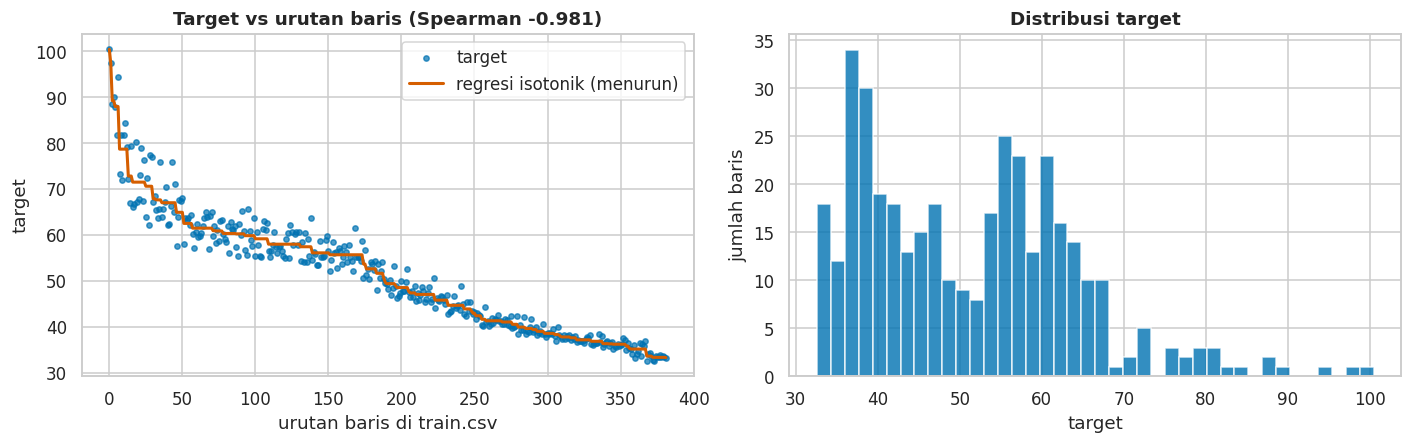

Simpangan target dari kurva isotonik in-sample: std 2.36 (target std 12.89)
20% baris pertama: rata-rata 69.3, std 9.7 | 80% sisanya: rata-rata 46.7, std 9.1


In [3]:
rho_pos = spearmanr(pos, y).correlation
INCREASING = bool(rho_pos > 0)
prior_in = prior_predict(pos, y, pos, INCREASING)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(np.arange(n_train), y, s=12, color=C1, alpha=0.7, label="target")
ax[0].plot(np.arange(n_train), prior_in, color=C2, lw=2, label="regresi isotonik (menurun)")
ax[0].set(xlabel="urutan baris di train.csv", ylabel="target", title=f"Target vs urutan baris (Spearman {rho_pos:.3f})"); ax[0].legend()
ax[1].hist(y, bins=40, color=C1, alpha=0.8)
ax[1].set(xlabel="target", ylabel="jumlah baris", title="Distribusi target")
save_fig(FIG_DIR, "01_target_order")
dev = y - prior_in
print(f"Simpangan target dari kurva isotonik in-sample: std {dev.std():.2f} (target std {y.std():.2f})")
print(f"20% baris pertama: rata-rata {y[pos <= 0.2].mean():.1f}, std {y[pos <= 0.2].std():.1f} | 80% sisanya: rata-rata {y[pos > 0.2].mean():.1f}, std {y[pos > 0.2].std():.1f}")

**Temuan.** Target turun hampir monoton dari awal sampai akhir file. Kurva isotonik in-sample menyisakan simpangan dengan std hanya 2,36, padahal std target 12,89: urutan baris sendirian menjelaskan sekitar 97% varians. Bagian awal file paling sulit: 20% baris pertama punya rata-rata 69,3 dan sebaran terbesar, termasuk nilai ekstrem sampai 100, sedangkan 80% sisanya rata-rata 46,7 dan jauh lebih rapat di sekitar kurva.

### 3.2 Fitur berkorelasi lemah dengan target, dan korelasinya mengikuti urutan baris

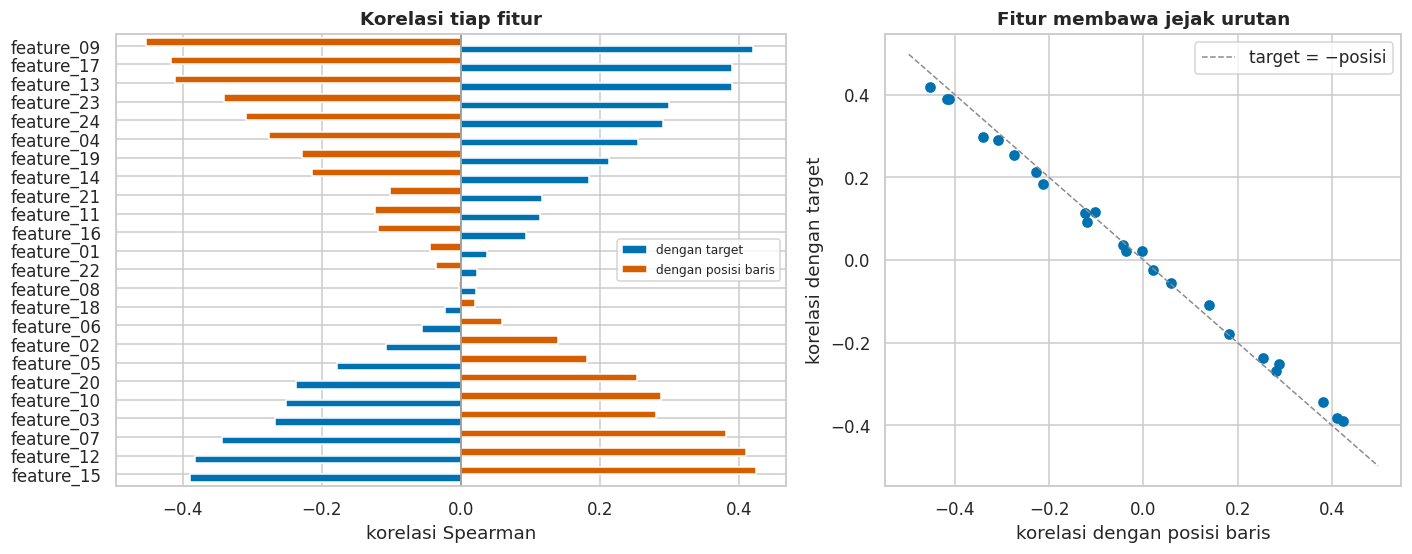

|korelasi| fitur terkuat dengan target: 0.420 (posisi: 0.981)
Korelasi antara kedua kolom korelasi: -0.999


In [4]:
corr = pd.DataFrame({
    "dengan target": [spearmanr(train[c], y).correlation for c in FEATURES],
    "dengan posisi baris": [spearmanr(train[c], pos).correlation for c in FEATURES],
}, index=FEATURES).sort_values("dengan target")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
corr.plot.barh(ax=ax[0], color=[C1, C2], width=0.8)
ax[0].axvline(0, color=CN, lw=1); ax[0].set(xlabel="korelasi Spearman", title="Korelasi tiap fitur"); ax[0].legend(fontsize=8)
ax[1].scatter(corr["dengan posisi baris"], corr["dengan target"], color=C1)
lim = np.abs(corr.values).max() * 1.1
ax[1].plot([-lim, lim], [lim, -lim], ls="--", color=CN, lw=1, label="target = −posisi")
ax[1].set(xlabel="korelasi dengan posisi baris", ylabel="korelasi dengan target", title="Fitur membawa jejak urutan"); ax[1].legend()
save_fig(FIG_DIR, "02_feature_corr")
print(f"|korelasi| fitur terkuat dengan target: {corr['dengan target'].abs().max():.3f} (posisi: {abs(rho_pos):.3f})")
print(f"Korelasi antara kedua kolom korelasi: {np.corrcoef(corr['dengan target'], corr['dengan posisi baris'])[0, 1]:.3f}")

**Temuan.** Fitur dengan korelasi terkuat terhadap target hanya mencapai |0,42|, jauh di bawah posisi baris (0,98). Grafik kanan menunjukkan bahwa korelasi fitur dengan target hampir persis sama dengan negatif korelasinya dengan posisi (korelasi −0,999). Dengan kata lain, fitur hanya informatif karena fitur itu juga tersusun menurut urutan file. Inilah alasan tim memakai posisi sebagai prior dan fitur hanya sebagai koreksi.

### 3.3 Apakah test disusun dengan urutan yang sama?

Prior posisi hanya berguna jika baris test juga diurutkan menurut target dengan cara yang sama. Target test tidak
diketahui, jadi dua bukti tidak langsung dipakai: (1) model yang **hanya** memakai fitur, tanpa informasi posisi, dilatih di
train lalu dipakai di test; jika prediksinya menurun terhadap urutan baris test, urutan test kemungkinan sama;
(2) adversarial validation untuk melihat apakah train dan test berasal dari distribusi fitur yang sama.

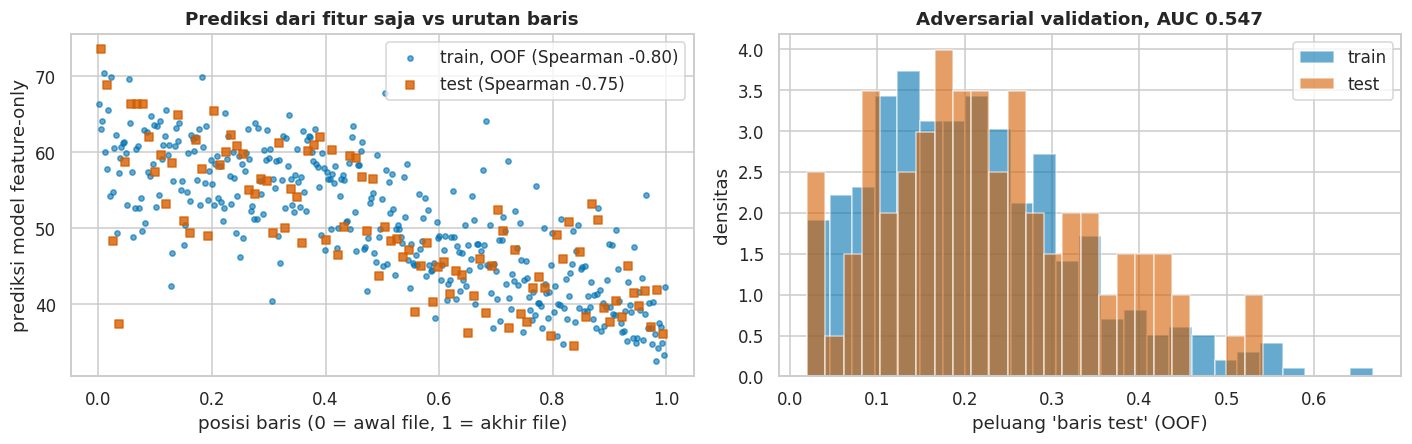

Feature-only OOF RMSE 8.4784 | bobot {'ridge': np.float64(0.0), 'svr_pca12': np.float64(0.552), 'krr_raw': np.float64(0.146), 'gp_ard': np.float64(0.302)}


In [5]:
# Model feature-only (jalur "strict" di notebook tim): 5-fold, blend NNLS dinormalisasi
strict_oof = {}
for tr, va in KFold(5, shuffle=True, random_state=SEED + 5).split(X):
    for n, (p,) in fit_predict_models(X[tr], y[tr], [X[va]], SEED).items():
        strict_oof.setdefault(n, np.zeros(n_train))[va] = p
S = np.column_stack([strict_oof[n] for n in MODEL_NAMES])
ws, _ = nnls(S, y); ws = ws / ws.sum()
STRICT_OOF = S @ ws
strict_full = fit_predict_models(X, y, [X_test], SEED)
STRICT_TEST = np.column_stack([strict_full[n][0] for n in MODEL_NAMES]) @ ws
rho_strict_tr = spearmanr(pos, STRICT_OOF).correlation
rho_strict_te = spearmanr(pos_test, STRICT_TEST).correlation

adv_X = np.vstack([X, X_test]); adv_y = np.r_[np.zeros(n_train), np.ones(n_test)]
adv_p = cross_val_predict(RandomForestClassifier(300, min_samples_leaf=3, random_state=SEED), adv_X, adv_y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
adv_auc = roc_auc_score(adv_y, adv_p)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(pos, STRICT_OOF, s=12, color=C1, alpha=0.6, label=f"train, OOF (Spearman {rho_strict_tr:.2f})")
ax[0].scatter(pos_test, STRICT_TEST, s=22, color=C2, marker="s", alpha=0.8, label=f"test (Spearman {rho_strict_te:.2f})")
ax[0].set(xlabel="posisi baris (0 = awal file, 1 = akhir file)", ylabel="prediksi model feature-only", title="Prediksi dari fitur saja vs urutan baris"); ax[0].legend()
ax[1].hist(adv_p[adv_y == 0], bins=25, alpha=0.6, density=True, color=C1, label="train")
ax[1].hist(adv_p[adv_y == 1], bins=25, alpha=0.6, density=True, color=C2, label="test")
ax[1].set(xlabel="peluang 'baris test' (OOF)", ylabel="densitas", title=f"Adversarial validation, AUC {adv_auc:.3f}"); ax[1].legend()
save_fig(FIG_DIR, "03_test_order")
print(f"Feature-only OOF RMSE {rmse(y, STRICT_OOF):.4f} | bobot {dict(zip(MODEL_NAMES, ws.round(3)))}")

**Temuan.** Model yang tidak pernah melihat posisi tetap menghasilkan prediksi test yang menurun terhadap urutan baris test (Spearman −0,75), hampir sama dengan pola di train (−0,80). Karena model hanya melihat fitur, pola ini berarti baris test kemungkinan besar diurutkan dengan cara yang sama seperti train. Adversarial validation memberi AUC 0,547, jadi distribusi fitur train dan test hampir sama. Kedua bukti ini membuat prior posisi layak dipakai untuk test, walaupun tetap merupakan asumsi tentang cara panitia menyusun file.

## 4. Desain validasi

Dengan hanya 382 baris dan target yang bergantung pada posisi, cara membagi fold menentukan angka yang dilaporkan. Tim
memakai dua skema sekaligus:

| Skema | Cara kerja | Yang diukur |
| --- | --- | --- |
| **Random repeated CV** (8 fold × 2 ulangan) | baris validasi berselang-seling dengan baris latih | situasi test, yang posisinya tersebar di sepanjang urutan |
| **Blocked CV** (10 blok posisi) | satu blok posisi utuh ditahan | skenario terburuk: prior harus mengekstrapolasi ke blok yang tidak terlihat |

Untuk mencegah kebocoran, label residual di setiap fold dihitung dari prior **out-of-fold di dalam fold latih**, bukan dari
prior in-sample. Prior untuk baris validasi dihitung dari seluruh fold latih.

In [6]:
rand_splits = list(RepeatedKFold(n_splits=RANDOM_SPLITS, n_repeats=RANDOM_REPEATS, random_state=SEED + 1).split(X))
blk_splits = block_splits(pos, N_BLOCKS)
t1 = time.time()
PR_R, RES_R = run_residual_cv(rand_splits, X, y, pos, INCREASING, SEED)
PR_B, RES_B = run_residual_cv(blk_splits, X, y, pos, INCREASING, SEED)
print(f"{len(rand_splits)} fold random + {len(blk_splits)} fold blocked selesai dalam {time.time() - t1:.0f} detik")
tail20, body80 = pos <= 0.2, pos > 0.2

16 fold random + 10 fold blocked selesai dalam 144 detik


## 5. Baseline

In [7]:
mean_r = np.zeros(n_train); c = np.zeros(n_train)
for tr, va in rand_splits:
    mean_r[va] += y[tr].mean(); c[va] += 1
mean_r /= c
mean_b = np.zeros(n_train)
for tr, va in blk_splits:
    mean_b[va] = y[tr].mean()
RESULTS = {
    "Rata-rata target": {"random CV": rmse(y, mean_r), "blocked CV": rmse(y, mean_b)},
    "Model feature-only (tanpa posisi)": {"random CV": rmse(y, STRICT_OOF), "blocked CV": np.nan},
    "Prior posisi saja": {"random CV": rmse(y, PR_R), "blocked CV": rmse(y, PR_B)},
}
pd.DataFrame(RESULTS).T.style.format("{:.4f}", na_rep="–")

,random CV,blocked CV
Rata-rata target,12.9105,14.1948
Model feature-only (tanpa posisi),8.4784,–
Prior posisi saja,2.9658,4.4287


**Temuan.** Menebak rata-rata memberi RMSE 12,9. Model terbaik yang hanya memakai fitur menurunkannya ke 8,48. Prior posisi saja langsung mencapai 2,97 pada random CV, hampir tiga kali lebih baik dari model fitur. Pada blocked CV prior naik ke 4,43, karena harus mengekstrapolasi ke blok posisi yang tidak terlihat, terutama di awal file (RMSE 8,84 pada 20% baris pertama).

## 6. Residual learning

Empat model mempelajari `residual = target − prior posisi` dari 24 fitur:

| Model | Konfigurasi | Karakter |
| --- | --- | --- |
| `ridge` | StandardScaler + Ridge(α=100) | linear, sangat teregularisasi |
| `svr_pca12` | StandardScaler + PCA(12, whiten) + SVR RBF | non-linear, tahan outlier |
| `krr_raw` | StandardScaler + Kernel Ridge RBF | non-linear halus |
| `gp_ard` | StandardScaler + Gaussian Process (Matern ν=2,5 dengan length-scale per fitur + white noise) | memilih fitur secara otomatis lewat length-scale |

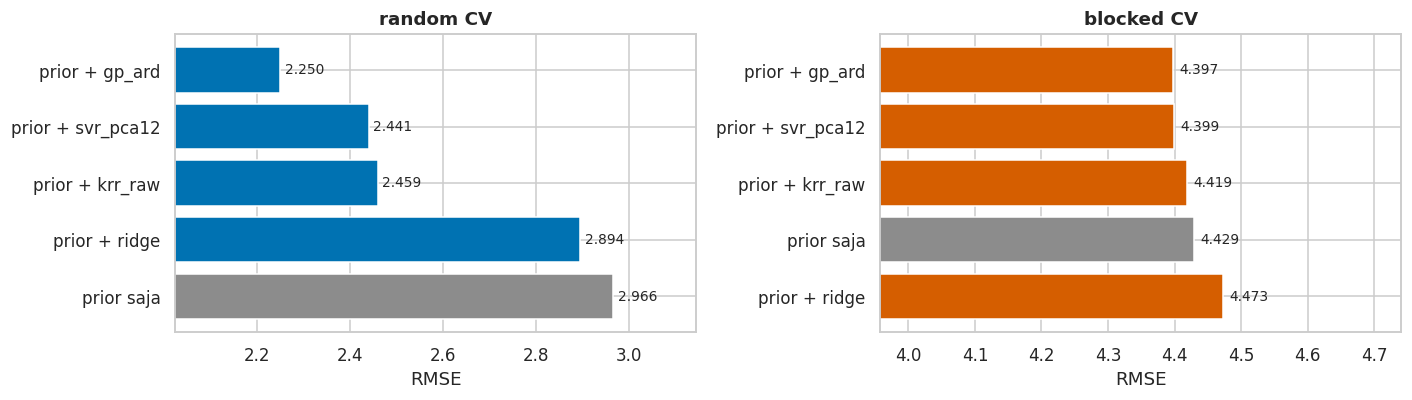

,random CV,blocked CV,blocked 20% awal,blocked 80% sisanya
model,,,,
prior saja,2.9658,4.4287,8.8382,2.2548
prior + ridge,2.8938,4.4727,8.7963,2.3992
prior + svr_pca12,2.4406,4.3986,8.6727,2.3391
prior + krr_raw,2.4595,4.4191,8.7507,2.3151
prior + gp_ard,2.2501,4.3974,8.8866,2.1275


In [8]:
rows = [{"model": "prior saja", "random CV": rmse(y, PR_R), "blocked CV": rmse(y, PR_B),
         "blocked 20% awal": rmse(y[tail20], PR_B[tail20]), "blocked 80% sisanya": rmse(y[body80], PR_B[body80])}]
for n in MODEL_NAMES:
    pr, pb = PR_R + RES_R[n], PR_B + RES_B[n]
    rows.append({"model": f"prior + {n}", "random CV": rmse(y, pr), "blocked CV": rmse(y, pb),
                 "blocked 20% awal": rmse(y[tail20], pb[tail20]), "blocked 80% sisanya": rmse(y[body80], pb[body80])})
cv_table = pd.DataFrame(rows).set_index("model")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, col, c_ in [(ax[0], "random CV", C1), (ax[1], "blocked CV", C2)]:
    s = cv_table[col].sort_values(ascending=False)
    a.barh(s.index, s.values, color=[CN if i == "prior saja" else c_ for i in s.index])
    for i, v in enumerate(s.values):
        a.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
    a.set(xlim=(s.min() * 0.9, s.max() * 1.06), xlabel="RMSE", title=col)
save_fig(FIG_DIR, "04_residual_models")
cv_table.style.format("{:.4f}")

**Temuan.** Di atas prior, GP-ARD memberi koreksi terbaik (random 2,250, blocked 4,398), disusul SVR+PCA12 dan Kernel Ridge. Ridge memperbaiki random CV sedikit tetapi memperburuk blocked CV, jadi hubungan residual dengan fitur tidak linear. Pada blocked CV semua model gagal memperbaiki 20% baris pertama secara berarti (8,67–8,89): nilai ekstrem di awal file tidak bisa dijelaskan fitur.

## 7. Blending dan skala koreksi

1. **NNLS** mencari bobot non-negatif untuk keempat residual yang meminimalkan galat pada gabungan OOF random dan blocked.
2. Koreksi gabungan dikalikan skala `s` antara 0 dan 1,2. Tim memilih `s` dengan **blocked RMSE terendah**, lalu
   membatasinya maksimal 1 agar koreksi tidak pernah diperbesar.

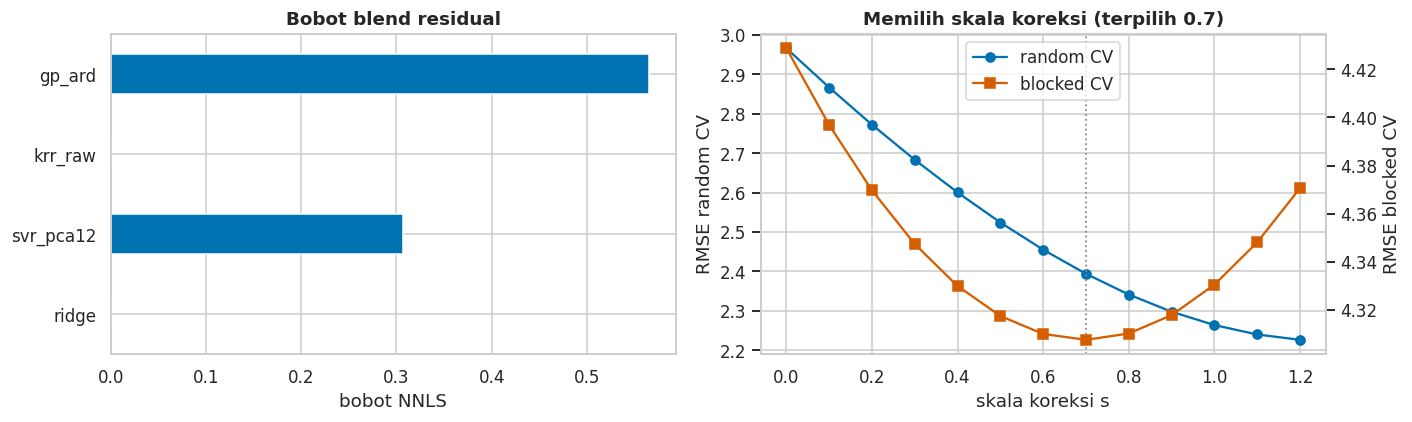

Bobot NNLS: {'ridge': 0.0, 'svr_pca12': 0.3069, 'krr_raw': 0.0, 'gp_ard': 0.5652} | RES_SCALE: 0.7
Prior saja   random 2.9658 | blocked 4.4287
Model akhir  random 2.3941 | blocked 4.3076 | gain blocked 0.1212


In [9]:
w = nnls_blend([RES_R, RES_B], [y - PR_R, y - PR_B], MODEL_NAMES)
blend_w = pd.Series(w, index=MODEL_NAMES)
blend_R = np.column_stack([RES_R[n] for n in MODEL_NAMES]) @ w
blend_B = np.column_stack([RES_B[n] for n in MODEL_NAMES]) @ w
scale_df = pd.DataFrame({"skala": SCALES, "random CV": [rmse(y, PR_R + s * blend_R) for s in SCALES],
                         "blocked CV": [rmse(y, PR_B + s * blend_B) for s in SCALES]})
RES_SCALE = min(float(scale_df.sort_values("blocked CV").iloc[0]["skala"]), 1.0)
FINAL_R, FINAL_B = PR_R + RES_SCALE * blend_R, PR_B + RES_SCALE * blend_B
RESULTS[f"Prior + {RES_SCALE} × blend residual (akhir)"] = {"random CV": rmse(y, FINAL_R), "blocked CV": rmse(y, FINAL_B)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
blend_w.plot.barh(ax=ax[0], color=C1); ax[0].set(xlabel="bobot NNLS", title="Bobot blend residual")
ax2 = ax[1].twinx()
ax[1].plot(scale_df["skala"], scale_df["random CV"], "o-", color=C1, label="random CV")
ax2.plot(scale_df["skala"], scale_df["blocked CV"], "s-", color=C2, label="blocked CV")
ax[1].axvline(RES_SCALE, color=CN, ls=":", lw=1.2)
ax[1].set(xlabel="skala koreksi s", ylabel="RMSE random CV", title=f"Memilih skala koreksi (terpilih {RES_SCALE})")
ax2.set_ylabel("RMSE blocked CV"); ax2.grid(False)
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, loc="upper center")
save_fig(FIG_DIR, "05_blend_scale")
print("Bobot NNLS:", blend_w.round(4).to_dict(), "| RES_SCALE:", RES_SCALE)
print(f"Prior saja   random {rmse(y, PR_R):.4f} | blocked {rmse(y, PR_B):.4f}")
print(f"Model akhir  random {rmse(y, FINAL_R):.4f} | blocked {rmse(y, FINAL_B):.4f} | gain blocked {rmse(y, PR_B) - rmse(y, FINAL_B):.4f}")

**Temuan.** NNLS memberi bobot 0,565 untuk GP-ARD dan 0,307 untuk SVR+PCA12, dan 0 untuk Ridge serta KRR. Random CV terus membaik sampai skala 1,2, tetapi blocked CV mencapai minimum di skala 0,7 lalu naik lagi; tim memilih 0,7 agar koreksi tidak berlebihan. Hasilnya random CV 2,966 → 2,394 dan blocked CV 4,429 → 4,308.

## 8. Diagnostik

### 8.1 Di bagian urutan mana koreksi membantu?

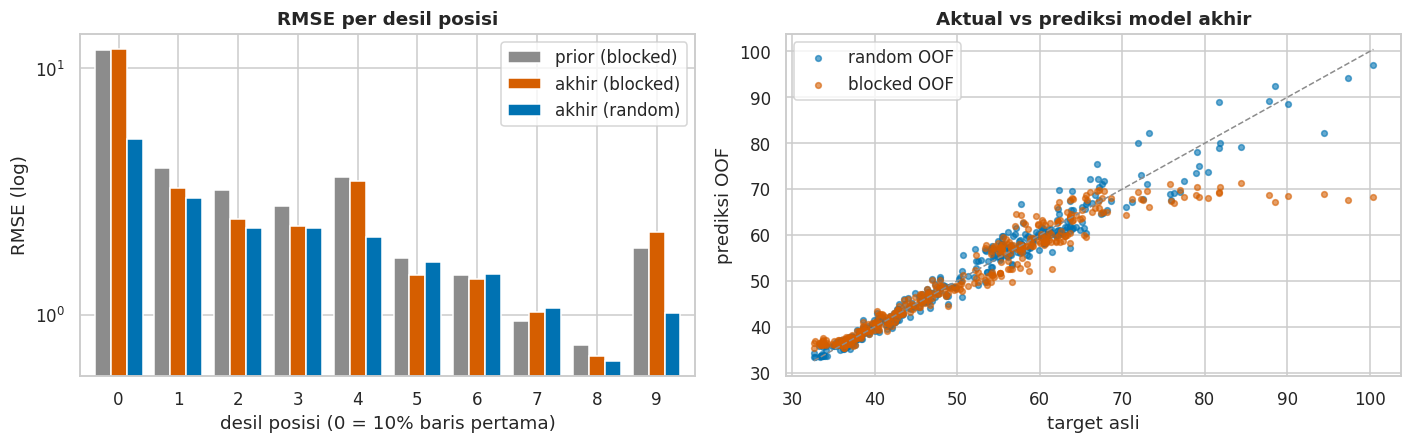

Desil yang membaik pada blocked CV: 7 / 10


,n,prior (blocked),akhir (blocked),akhir (random),gain blocked
desil posisi,,,,,
0,38,11.868,11.918,5.182,-0.050
1,38,3.922,3.265,2.982,0.656
2,39,3.193,2.441,2.241,0.751
3,38,2.751,2.290,2.245,0.461
4,38,3.603,3.497,2.065,0.105
5,38,1.694,1.446,1.640,0.248
6,38,1.450,1.400,1.456,0.050
7,39,0.941,1.022,1.062,-0.081
8,38,0.754,0.678,0.650,0.076


In [10]:
dec = np.minimum((pos * 10).astype(int), 9)
rep = pd.DataFrame([{"desil posisi": d, "n": int((dec == d).sum()), "prior (blocked)": rmse(y[dec == d], PR_B[dec == d]),
                     "akhir (blocked)": rmse(y[dec == d], FINAL_B[dec == d]), "akhir (random)": rmse(y[dec == d], FINAL_R[dec == d])}
                    for d in range(10)]).set_index("desil posisi")
rep["gain blocked"] = rep["prior (blocked)"] - rep["akhir (blocked)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
rep[["prior (blocked)", "akhir (blocked)", "akhir (random)"]].plot.bar(ax=ax[0], color=[CN, C2, C1], width=0.8)
ax[0].set(yscale="log", xlabel="desil posisi (0 = 10% baris pertama)", ylabel="RMSE (log)", title="RMSE per desil posisi"); ax[0].tick_params(axis="x", rotation=0)
ax[1].scatter(y, FINAL_R, s=14, alpha=0.6, color=C1, label="random OOF")
ax[1].scatter(y, FINAL_B, s=14, alpha=0.6, color=C2, label="blocked OOF")
ax[1].plot([y.min(), y.max()], [y.min(), y.max()], "--", color=CN, lw=1)
ax[1].set(xlabel="target asli", ylabel="prediksi OOF", title="Aktual vs prediksi model akhir"); ax[1].legend()
save_fig(FIG_DIR, "06_deciles")
print("Desil yang membaik pada blocked CV:", int((rep["gain blocked"] > 0).sum()), "/ 10")
rep.style.format({c: "{:.3f}" for c in rep.columns if c != "n"})

**Temuan.** Koreksi memperbaiki 7 dari 10 desil posisi pada blocked CV, dengan gain terbesar di desil 1–3 (0,46–0,75). Desil 0, 7, dan 9 sedikit memburuk. Desil 0 (10% baris pertama) tetap jauh lebih sulit daripada yang lain: RMSE blocked sekitar 11,9 dan random 5,2, dibanding 0,7–3,5 untuk desil lain. Grafik kanan memperlihatkan bahwa nilai target tertinggi diprediksi terlalu rendah, terutama pada blocked CV.

## 9. Submission

Label residual untuk fit akhir memakai prior OOF seluruh train (10 fold × 5 ulangan), prior test dihitung dari seluruh
train pada posisi baris test, lalu `prediksi = prior_test + RES_SCALE × blend residual`. Prediksi di-clip ke
`[min(target) − 2, max(target) + 2]`.

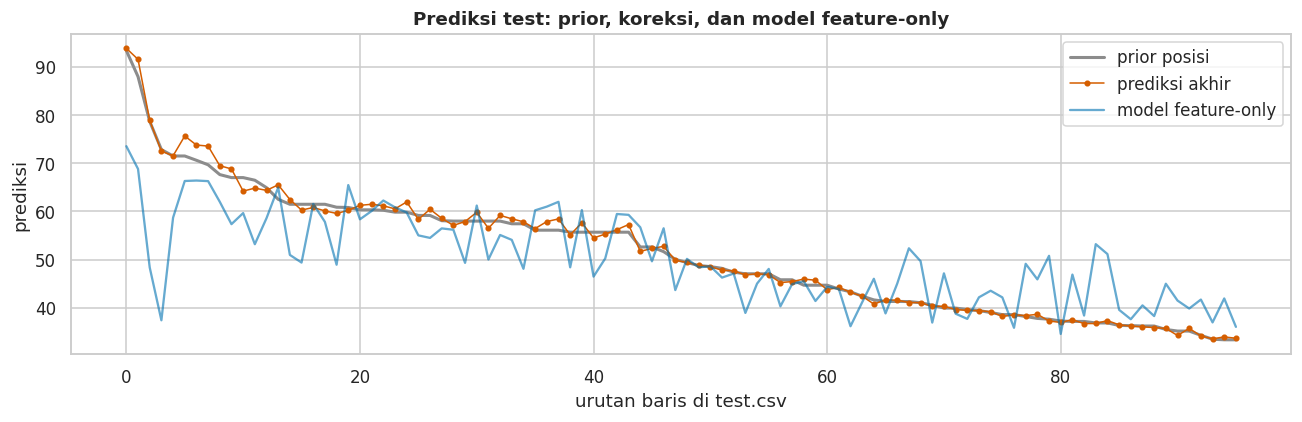

Rata-rata |koreksi| di test: 0.813 | korelasi koreksi dengan prediksi feature-only − prior: 0.049


,random CV,blocked CV
Rata-rata target,12.9105,14.1948
Model feature-only (tanpa posisi),8.4784,–
Prior posisi saja,2.9658,4.4287
Prior + 0.7 × blend residual (akhir),2.3941,4.3076


In [11]:
full_res_target = y - full_oof_prior(pos, y, INCREASING)
PRIOR_TEST = prior_predict(pos, y, pos_test, INCREASING)
full_preds = fit_predict_models(X, full_res_target, [X_test], SEED)
res_test = np.column_stack([full_preds[n][0] for n in MODEL_NAMES]) @ w
FINAL_TEST = np.clip(PRIOR_TEST + RES_SCALE * res_test, y.min() - 2, y.max() + 2)
sub = pd.DataFrame({ID: test[ID].values, "prediction": FINAL_TEST})
assert len(sub) == n_test and sub[ID].is_unique and np.isfinite(sub.prediction).all()
sub.to_csv(OUT_DIR / "submission.csv", index=False)
pd.DataFrame(RESULTS).T.to_csv(OUT_DIR / "cv_results.csv")
cv_table.to_csv(OUT_DIR / "residual_models.csv"); scale_df.to_csv(OUT_DIR / "scale_scan.csv", index=False)
pd.DataFrame({ID: test[ID].values, "posisi": pos_test, "prior": PRIOR_TEST, "koreksi": RES_SCALE * res_test,
              "akhir": FINAL_TEST, "feature_only": STRICT_TEST}).to_csv(OUT_DIR / "test_decomposition.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.arange(n_test), PRIOR_TEST, color=CN, lw=2, label="prior posisi")
ax.plot(np.arange(n_test), FINAL_TEST, "o-", ms=3, color=C2, lw=1, label="prediksi akhir")
ax.plot(np.arange(n_test), STRICT_TEST, color=C1, alpha=0.6, label="model feature-only")
ax.set(xlabel="urutan baris di test.csv", ylabel="prediksi", title="Prediksi test: prior, koreksi, dan model feature-only"); ax.legend()
save_fig(FIG_DIR, "07_test_predictions")
print(f"Rata-rata |koreksi| di test: {np.abs(RES_SCALE * res_test).mean():.3f} | korelasi koreksi dengan prediksi feature-only − prior: "
      f"{np.corrcoef(res_test, STRICT_TEST - PRIOR_TEST)[0, 1]:.3f}")
pd.DataFrame(RESULTS).T.style.format("{:.4f}", na_rep="–")

**Temuan.** Koreksi residual di test rata-rata hanya 0,81 poin, sehingga prediksi akhir hampir mengikuti prior posisi, dengan penyesuaian terbesar di 15 baris pertama. Koreksi itu hampir tidak berkorelasi (0,05) dengan selisih model feature-only terhadap prior, jadi residual model memakai informasi yang berbeda dari model fitur biasa.

## 10. Kesimpulan

1. **Urutan file adalah sinyal utama.** Spearman posisi vs target −0,981, sedangkan fitur terkuat hanya 0,42, dan korelasi fitur dengan target hanyalah cermin korelasinya dengan posisi.
2. **Fitur tetap berguna sebagai koreksi.** Residual learning dengan label prior out-of-fold menurunkan random CV dari 2,966 ke 2,394 tanpa bocor, dan blend diredam ke 0,7× berdasarkan blocked CV.
3. **Awal file adalah titik lemah.** 10% baris pertama memuat target tertinggi dan paling bervariasi; di sana prior dan fitur sama-sama gagal (RMSE blocked sekitar 12).
4. **Hasil leaderboard.** Public 2,248 (sesuai random CV 2,394) tetapi private 3,081. Public hanya 29 baris, jadi selisih ini wajar jika private memuat lebih banyak baris dari awal file yang sulit; dugaan ini tidak bisa diverifikasi karena pembagian public/private tidak dipublikasikan. Tim finis peringkat 4 dari 13.

**Keterbatasan.** Seluruh metode bergantung pada asumsi bahwa baris test diurutkan seperti train. Buktinya kuat tetapi tidak langsung. Jika urutan tidak boleh dipakai, model feature-only (RMSE 8,48) adalah gambaran jujur dari informasi yang ada di fitur.

### Jejak lingkungan

In [12]:
import platform
pkgs = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn"]
print(" | ".join([f"python {platform.python_version()}"] + [f"{p} {version(p)}" for p in pkgs]))
print(f"Waktu eksekusi total: {(time.time() - T0) / 60:.1f} menit")

python 3.13.18 | numpy 2.1.3 | pandas 2.3.3 | scikit-learn 1.6.1 | scipy 1.16.3 | matplotlib 3.10.0 | seaborn 0.13.2
Waktu eksekusi total: 3.4 menit
